# 3. Analyze an ADARA file, as a Python library

Reads a recorded ADARA packet file: the same packets the beamline's stream management service
(SMS) sends live, saved to disk. Unlike NeXus, ADARA carries true per-pulse timing and proton
charge in its RTDL packets, so the error-decay series here is measured, not attributed.

Diamond run 244114 is recorded as 16 files of about 210 MB each. `--adara-file` reads one file, so
this notebook analyzes the first, `m00000001-f00000001`, which holds the run's first ~18 s of beam.
The run's `END_RUN` is only in the last file, so the analyzer finalizes the histogram when the file
ends. To replay the whole run, use the stream notebooks (`04_analyze_adara_stream_*`).

Run directory: `../nomad-adara-carbon-share/20260619-140639.403016382-run-244114/`

**Before you start:** run `01_preparer_cli.ipynb` or `01_preparer_python.ipynb` once. They write the
pixel geometry, background and normalization CSVs into `notebooks/output/` that every analyze
notebook reads.

**Runtime:** about a minute for one file, and up to 6 minutes the first time it is read over the NFS
share; the reading is I/O bound. Copying the file to local disk makes it faster.

## Setup

Every path below is relative to the repository root, so the commands are the same ones you would
type in a terminal from there.

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root so every path matches the README and the terminal commands.
REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
os.chdir(REPO_ROOT)
# Shell cells resolve `live_stream_analysis` and `python` from this kernel's environment.
os.environ["PATH"] = f"{Path(sys.executable).parent}{os.pathsep}{os.environ['PATH']}"

OUTPUT_DIR = Path("notebooks/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Working directory: {Path.cwd()}")

ADARA_FILE = Path("../nomad-adara-carbon-share/20260619-140639.403016382-run-244114/m00000001-f00000001-run-244114.adara")
if not ADARA_FILE.exists():
    raise FileNotFoundError(f"{ADARA_FILE} not found; mount the carbon NFS share next to the repository")
# True: show the live plot inside this notebook. False: open it in a browser tab instead.
LIVE_PLOT_INLINE = True

for prepared in ["pixel_geometry_calibrated.csv", "background.csv", "normalization.csv", "diamond_reflections.csv"]:
    if not (OUTPUT_DIR / prepared).exists():
        raise FileNotFoundError(f"{OUTPUT_DIR / prepared} is missing; run a 01_preparer notebook first")

Working directory: /home/ntm/projects/illumine/live_stream_analysis


## Run it

`start_analysis` takes the CLI options as keywords: the flag name with underscores instead of
dashes, a list for a repeatable flag such as `nexus_file`, a `(host, port)` pair for
`adara_stream`, and `True` for an on/off flag. The CLI's own parser validates them, so the defaults
and error messages are identical to the terminal, and a typo raises before anything starts.

It returns an `AnalysisRun` handle:

| Method | Does |
| --- | --- |
| `show()` | Embed the live plot in the cell output |
| `plot_state()` | The plot's current data, including a `status` summary |
| `wait()` | Block until the analysis finishes |
| `wait_for_log(text)` | Block until a log line appears, such as a completed run on a live stream |
| `log()` | The last lines of the analyzer's output |
| `stop()` | Interrupt the analyzer and shut down the plot |
| `command` | The equivalent shell command |

`live_plot="inline"` (the default) serves the plot for `show()`; `"browser"` also opens a tab; `None`
disables it.

| Option | Why |
| --- | --- |
| `--adara-file` | One recorded ADARA file |
| `--live-plot-refresh-every 200` | Refresh every 200 packets; this file has about 9,000 |
| `--histogram-pixel-geometry-csv` | Per-pixel TOF→Q constants from the preparer, here with the 2026-06-09 calibration applied |
| `--histogram-q-min/-max/-bin-size` | 0–40 1/Å in 0.02 bins, the same binning the preparer used for background and vanadium |
| `--tof-tick-us 0.1` | ADARA event TOF is in 100 ns ticks. Checked on run 244114: with 0.1 the histogram overlays NOM_243708's, and 21 diamond reflections land within 0.04 1/Å; with 1.0 every peak sits at a tenth of its Q |
| `--background-subtraction`, `--normalization` | The empty-can and vanadium CSVs from the preparer |
| `--normalize-by proton-charge` | The default, spelled out: sample, background and vanadium are each divided by their own charge |
| `--histogram-output-csv` | The corrected I(Q) |
| `--statistics-output-csv`, `--statistics-q-min/-max` | The error-decay series, over the 2–18 1/Å range where diamond has its strong reflections |
| `--live-plot-*` | Browser plot on a fixed port, kept open after the analysis, without opening a browser tab |

In [2]:
from live_stream_analysis.notebook import start_analysis

run = start_analysis(
    live_plot="inline" if LIVE_PLOT_INLINE else "browser",
    log_file=OUTPUT_DIR / "adara_file_python.log",
    adara_file=ADARA_FILE,
    histogram_pixel_geometry_csv=OUTPUT_DIR / "pixel_geometry_calibrated.csv",
    histogram_q_min=0.0,
    histogram_q_max=40.0,
    histogram_q_bin_size=0.02,
    tof_tick_us=0.1,
    background_subtraction=OUTPUT_DIR / "background.csv",
    normalization=OUTPUT_DIR / "normalization.csv",
    normalize_by="proton-charge",
    histogram_output_csv=OUTPUT_DIR / "adara_file_python_iq.csv",
    statistics_output_csv=OUTPUT_DIR / "adara_file_python_statistics.csv",
    statistics_q_min=2.0,
    statistics_q_max=18.0,
    live_plot_refresh_every=200,
    event_log_interval=10_000_000,
)
print(run.command)  # the equivalent terminal command
run

live_stream_analysis analyze --adara-file ../nomad-adara-carbon-share/20260619-140639.403016382-run-244114/m00000001-f00000001-run-244114.adara --histogram-pixel-geometry-csv notebooks/output/pixel_geometry_calibrated.csv --histogram-q-min 0.0 --histogram-q-max 40.0 --histogram-q-bin-size 0.02 --tof-tick-us 0.1 --background-subtraction notebooks/output/background.csv --normalization notebooks/output/normalization.csv --normalize-by proton-charge --histogram-output-csv notebooks/output/adara_file_python_iq.csv --statistics-output-csv notebooks/output/adara_file_python_statistics.csv --statistics-q-min 2.0 --statistics-q-max 18.0 --live-plot-refresh-every 200 --event-log-interval 10000000 --live-plot-mode browser --live-plot-keep-open --live-plot-no-open-browser --live-plot-port 45175


<AnalysisRun running url=http://127.0.0.1:45175/ log=/home/ntm/projects/illumine/live_stream_analysis/notebooks/output/adara_file_python.log>

### How the live plot gets into the notebook

`live_plot_mode browser` makes the analyzer serve its plot page from a small HTTP server on its own
thread, and the page polls that server twice a second. Because the page talks to the analyzer and
not to the notebook kernel, it can sit in a cell output and keep updating while the kernel does
other things. The analysis therefore runs as a background process, and `show()` embeds the page
once the server is up.

`--live-plot-keep-open` keeps the page up after the analysis finishes, showing **Analysis complete**,
until you call `stop()`. Set `LIVE_PLOT_INLINE = False` above to open the same page in a browser
tab instead. The page loads Chart.js from a CDN, so it needs internet access.

In [3]:
if LIVE_PLOT_INLINE:
    run.show()
else:
    import webbrowser

    run.wait_for_plot()
    webbrowser.open(run.url)
    print(f"Live plot opened at {run.url}")

In [4]:
import time

# Re-run this cell any time for a progress snapshot; the analysis keeps going in the background.
deadline = time.monotonic() + 120
while run.plot_state()["status"]["update_count"] == 0 and time.monotonic() < deadline:
    time.sleep(2)
status = run.plot_state()["status"]
print(
    f"updates={status['update_count']}  elapsed={status['elapsed_seconds']:.1f} s  "
    f"charge={status['proton_charge_pc']:.3g} pC  mean sigma/I={status['mean_relative_uncertainty']:.4f}"
)

updates=1  elapsed=0.0 s  charge=0 pC  mean sigma/I=0.0000


## Wait for it to finish

The live plot keeps updating above while this cell waits.

In [5]:
run.wait()
print(run.log(22))

2026-10-21 15:16:05,785 INFO live_stream_analysis.analyzer.histogram_runner: Loaded pixel geometry for 101376 detector ids
2026-10-21 15:16:05,786 INFO live_stream_analysis.analyzer.histogram_runner: Background subtraction enabled: /home/ntm/projects/illumine/live_stream_analysis/notebooks/output/background.csv
2026-10-21 15:16:05,786 INFO live_stream_analysis.analyzer.histogram_runner: Background CSV exposure totals: CorrectionTotals(proton_charge_pc=4000364135190.0, duration_s=2885.64709473)
2026-10-21 15:16:05,786 INFO live_stream_analysis.analyzer.histogram_runner: Normalization enabled: /home/ntm/projects/illumine/live_stream_analysis/notebooks/output/normalization.csv
2026-10-21 15:16:05,787 INFO live_stream_analysis.analyzer.histogram_runner: Normalization CSV exposure totals: CorrectionTotals(proton_charge_pc=2000601000470.0, duration_s=1443.90686035)
2026-10-21 15:16:05,805 INFO live_stream_analysis.analyzer.histogram_runner: Histogram CSV output will be written to /home/ntm/p

## Results

The corrected I(Q) is background-subtracted and vanadium-normalized, with sample, background and
vanadium each divided by their own proton charge. Dashed lines mark the expected diamond
reflections (a = 3.56712 Å), as an absolute check on the Q axis. The right panel is the error-decay
series the INTERSECT forecasting service consumes: for counting statistics, the mean σ/I(Q) should
fall as 1/√charge.

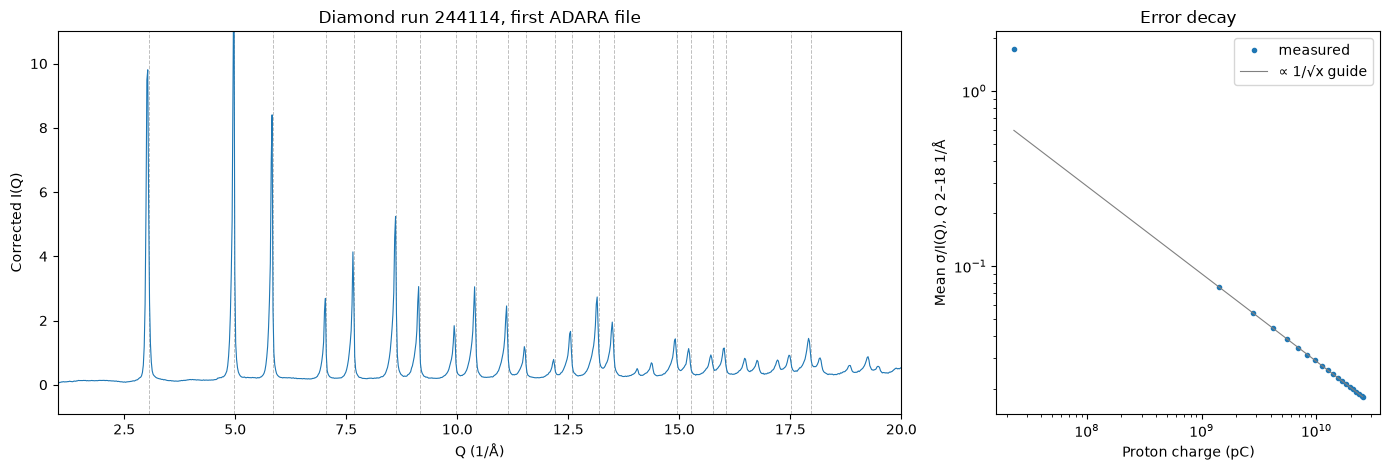

20 decay samples; final mean sigma/I = 0.0180 at 2.526e+10 (Proton charge (pC))


In [6]:
import matplotlib.pyplot as plt
import numpy as np

from live_stream_analysis.notebook import read_csv

iq = read_csv(OUTPUT_DIR / "adara_file_python_iq.csv")
statistics = read_csv(OUTPUT_DIR / "adara_file_python_statistics.csv")
reflections = read_csv(OUTPUT_DIR / "diamond_reflections.csv")

q, intensity, error = iq["Q value"], iq["I(Q)"], iq["Error I(Q)"]
window = (q > 1.0) & (q < 20.0)
low, high = np.nanpercentile(intensity[window], [0.5, 99.9])

fig, (ax_iq, ax_decay) = plt.subplots(1, 2, figsize=(14, 4.8), width_ratios=[2.2, 1])
for q_peak in reflections["Q (1/A)"][reflections["rel intensity"] > 0.5]:
    ax_iq.axvline(q_peak, color="0.75", linestyle="--", linewidth=0.7, zorder=0)
ax_iq.fill_between(q, intensity - error, intensity + error, alpha=0.3, linewidth=0)
ax_iq.plot(q, intensity, linewidth=0.8)
ax_iq.set(
    xlim=(1.0, 20.0),
    ylim=(low - 0.1 * (high - low), high + 0.1 * (high - low)),
    xlabel="Q (1/Å)",
    ylabel="Corrected I(Q)",
    title="Diamond run 244114, first ADARA file",
)

charge = statistics["Proton charge (pC)"]
x_values, x_label = (charge, "Proton charge (pC)") if np.nanmax(charge) > 0 else (statistics["Elapsed time (s)"], "Elapsed time (s)")
sigma = statistics["Mean sigma/I(Q)"]
measured = x_values > 0  # the first sample can land before any charge or time has accrued
x_values, sigma = x_values[measured], sigma[measured]
ax_decay.loglog(x_values, sigma, marker=".", linestyle="none", label="measured")
# Anchored on the last, best-determined sample; the earliest ones carry almost no counts.
ax_decay.loglog(x_values, sigma[-1] * np.sqrt(x_values[-1] / x_values), color="0.5", linewidth=0.8, label="∝ 1/√x guide")
ax_decay.set(xlabel=x_label, ylabel="Mean σ/I(Q), Q 2–18 1/Å", title="Error decay")
ax_decay.legend()
fig.tight_layout()
plt.show()

print(f"{len(sigma)} decay samples; final mean sigma/I = {sigma[-1]:.4f} at {x_values[-1]:.4g} ({x_label})")

## Stop

`stop()` interrupts the analyzer as Ctrl-C would and shuts down the plot server. Everything above
was already written to `notebooks/output/`, so nothing is lost.

In [7]:
print(f"Analyzer exit code {run.stop()} (130 means it was interrupted, as intended)")

Analyzer exit code 130 (130 means it was interrupted, as intended)
